In [2]:
from google.colab import files
uploaded = files.upload()   # choose "02 computer.xlsx" in the popup

Saving 02 computer.xlsx to 02 computer (1).xlsx


In [3]:
import pandas as pd

df = pd.read_excel("02 computer.xlsx")
print(df.shape)      # should be (14, 5)
df

(14, 5)


,age,income,student,credit_rating,buys_computer
0,<=30,high,no,fair,no
1,<=30,high,no,excellent,no
2,31...40,high,no,fair,yes
3,>40,medium,no,fair,yes
4,>40,low,yes,fair,yes
5,>40,low,yes,excellent,no
6,31...40,low,yes,excellent,yes
7,<=30,medium,no,fair,no
8,<=30,low,yes,fair,yes
9,>40,medium,yes,fair,yes


In [4]:
X = df.drop(columns="buys_computer")
y = df["buys_computer"]

X_encoded = pd.get_dummies(X)   # one-hot encoding
X_encoded.head()

,age_31...40,age_<=30,age_>40,income_high,income_low,income_medium,student_no,student_yes,credit_rating_excellent,credit_rating_fair
0,False,True,False,True,False,False,True,False,False,True
1,False,True,False,True,False,False,True,False,True,False
2,True,False,False,True,False,False,True,False,False,True
3,False,False,True,False,False,True,True,False,False,True
4,False,False,True,False,True,False,False,True,False,True


In [5]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(criterion="entropy", random_state=42)
tree.fit(X_encoded, y)
print("Training accuracy:", tree.score(X_encoded, y))

Training accuracy: 1.0


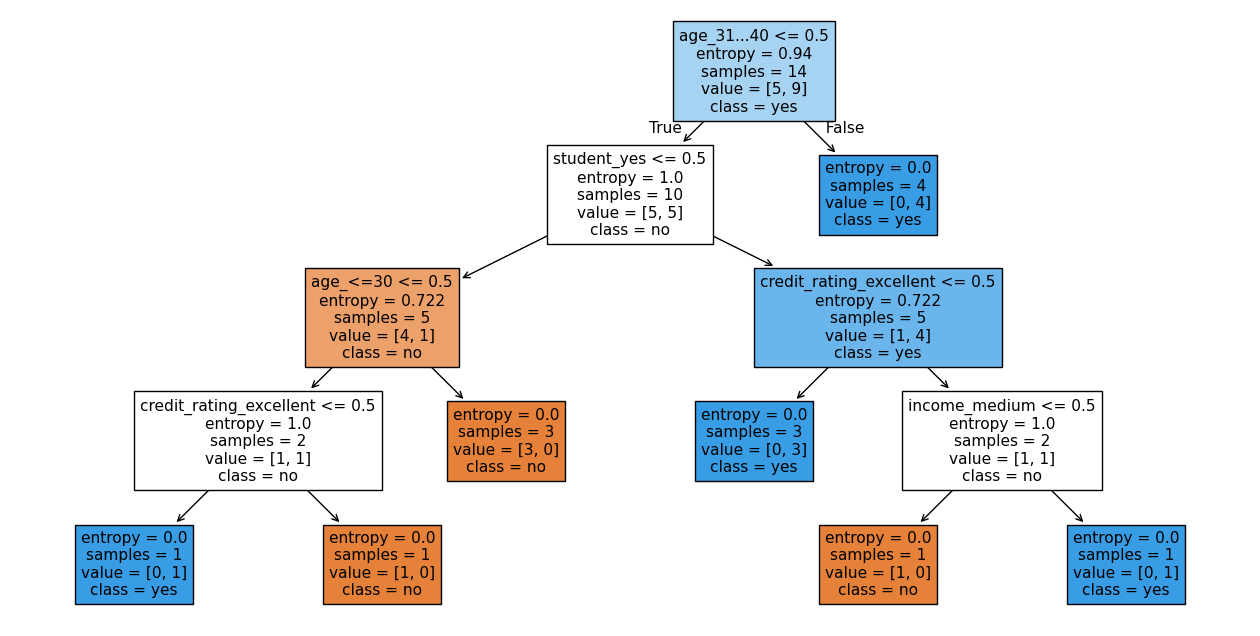

In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=X_encoded.columns,
          class_names=tree.classes_, filled=True)
plt.show()

In [7]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB

enc = OrdinalEncoder()
X_ord = enc.fit_transform(X)

nb = CategoricalNB()
nb.fit(X_ord, y)
print("Naive Bayes training accuracy:", nb.score(X_ord, y))

Naive Bayes training accuracy: 0.9285714285714286


In [8]:
new = pd.DataFrame([{"age": "<=30", "income": "medium",
                     "student": "yes", "credit_rating": "fair"}])

# Decision tree
new_encoded = pd.get_dummies(new).reindex(columns=X_encoded.columns, fill_value=0)
print("Tree prediction:", tree.predict(new_encoded)[0])

# Naive Bayes
print("NB prediction:", nb.predict(enc.transform(new))[0])

Tree prediction: yes
NB prediction: yes


In [9]:
from sklearn.model_selection import cross_val_score, LeaveOneOut

scores = cross_val_score(tree, X_encoded, y, cv=LeaveOneOut())
print("Leave-one-out accuracy:", scores.mean())

Leave-one-out accuracy: 0.5714285714285714
